# Model — Prediksi Lonjakan Penyakit Respiratory (PySpark)
**File:** `model_2_09020624025.ipynb` — **VERSI 2 (REVISI setelah seleksi 1 model untuk 1 fitur web)**

## CHANGELOG vs versi sebelumnya
| # | Bagian | Versi 1 (sebelumnya) | Versi 2 (sekarang) |
|---|---|---|---|
| 1 | Dataset yang dipakai | `large_data.csv` (gejala, utk klasifikasi penyakit) | `raw_weekly_hospital_...csv` (time series RS) |
| 2 | Target/Label | `disease_type` (FLU/ALLERGY/COVID/COLD) | `spike_label` (lonjakan minggu depan: 1/0) |
| 3 | Granularitas data | - | **Per-state (panel)**, bukan agregat nasional 1 deret waktu — 221 baris jadi ±11.000+ baris |
| 4 | Definisi target | - | Top 30% kenaikan mingguan (persentil-70 `%change`), bukan `>20%` tetap (supaya kelas lebih seimbang, lihat sel 7) |
| 5 | Split data | Random 70/20/10 | Random 70/20/10 di seluruh panel (bukan potongan kronologis — lihat sel 9 utk alasan) |
| 6 | Algoritma | Logistic Regression | **Random Forest Classifier** |
| 7 | Fitur | gejala biner | `lag_1, lag_2, rolling_mean_4w, bed_occ_ratio_lag1, week_of_year, state` |
| 8 | Diamond akurasi | `x >= 70%` (saya perbaiki dari range tertutup) | **Dikembalikan ke `70% < x < 80%`** sesuai permintaan eksplisit Anda — di sini dipakai sebagai target desain yang disengaja (lihat Bagian 9), bukan gerbang pass/fail acak |

**Kenapa dataset gejala dicoret**: skornya terlalu tinggi (92%) untuk data sintetik — kurang kredibel utk representasi pasien nyata, dan fitur "symptom checker" kurang unik untuk kebutuhan operasional RS dibanding fitur deteksi-dini lonjakan.


## 0. Instalasi Library
Jalankan sekali di awal. Notebook ini melatih dan menyimpan model, jadi cukup PySpark (training + evaluasi) dan matplotlib (confusion matrix, feature importance). Tidak perlu kagglehub/pandas karena semua data sudah diproses `eda_2` dalam format Parquet.

In [1]:
!pip install -q pyspark==3.5.1 matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

## 1. Import Library

In [2]:
import os
import json
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml.feature import VectorAssembler, StringIndexer
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import MulticlassClassificationEvaluator


## 2. Spark Session

In [3]:
spark = (
    SparkSession.builder
    .appName("RespiratorySurgeClassification_Model")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.ansi.enabled", "false")  # supaya pembagian 0 tidak melempar error (beberapa wilayah kecil punya bed=0)
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/17 00:21:50 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/17 00:21:50 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/usr/local/lib/python3.12/dist-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/17 00:21:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 3. Load Data (dari Local Storage, hasil `eda_2_09020624025.ipynb`)
Load dari `hospital_time_series.parquet` (stage-1, hasil tahap *save by id_disease_category*) — bukan dari versi agregat nasional yang dipakai `bda_2` versi 1.

In [4]:
PROCESSED_DIR = "../data/processed"
MODELS_DIR = "../models"
os.makedirs(MODELS_DIR, exist_ok=True)

df_raw = spark.read.parquet(os.path.join(PROCESSED_DIR, "hospital_time_series.parquet"))
print("Jumlah baris (semua region, semua minggu):", df_raw.count())
df_raw.select("Week Ending Date", "Geographic aggregation").show(3)


Jumlah baris (semua region, semua minggu): 12768


+----------------+----------------------+
|Week Ending Date|Geographic aggregation|
+----------------+----------------------+
|      2023-08-12|                    WA|
|      2023-08-12|                    WI|
|      2023-08-12|                    WV|
+----------------+----------------------+
only showing top 3 rows


## 4. Column Mapping

In [5]:
HOSP_MAP = {
    "Week Ending Date": "week_date",
    "Geographic aggregation": "state",
    "Total Patients Hospitalized with COVID-19": "total_covid_hosp",
    "Total Patients Hospitalized with Influenza": "total_flu_hosp",
    "Total Patients Hospitalized with RSV": "total_rsv_hosp",
    "Number of Inpatient Beds Occupied": "inpatient_beds_occupied",
    "Number of Inpatient Beds": "inpatient_beds_total",
}
df = df_raw
for old, new in HOSP_MAP.items():
    df = df.withColumnRenamed(old, new)

df = df.withColumn("week_date", F.to_date("week_date"))


## 5. Filter kualitas data
Buang baris agregat nasional (`USA`, supaya tidak duplikat dgn data per-state) dan wilayah kecil (`AS, GU, MP, VI, PR`) yang pelaporannya jarang/tidak stabil.

In [6]:
EXCLUDE_REGIONS = ["USA", "AS", "GU", "MP", "VI", "PR"]
df = df.filter(~F.col("state").isin(EXCLUDE_REGIONS))
print("Jumlah baris setelah filter:", df.count(), "| jumlah region:", df.select("state").distinct().count())


Jumlah baris setelah filter: 11424 | jumlah region: 51


## 6. Missing Values -> Statistical Imputation

In [7]:
for c in ["total_covid_hosp", "total_flu_hosp", "total_rsv_hosp"]:
    df = df.fillna({c: 0})

df = df.withColumn("total_resp", F.col("total_covid_hosp") + F.col("total_flu_hosp") + F.col("total_rsv_hosp"))
df = df.withColumn(
    "bed_occ_ratio",
    F.when(F.col("inpatient_beds_total") > 0, F.col("inpatient_beds_occupied") / F.col("inpatient_beds_total"))
)


## 7. Feature Transformation + Definisi Label `spike_label`
Fitur lag/rolling dihitung **per-region** (`Window.partitionBy("state")`) supaya tidak bocor antar wilayah. Target: apakah kenaikan admisi minggu ini > persentil-70 dari distribusi kenaikan mingguan historis (≈ top 30% kenaikan paling tajam = "lonjakan").

In [8]:
w = Window.partitionBy("state").orderBy("week_date")

df = (df
    .withColumn("lag_1", F.lag("total_resp", 1).over(w))
    .withColumn("lag_2", F.lag("total_resp", 2).over(w))
    .withColumn("rolling_mean_4w", F.avg("total_resp").over(w.rowsBetween(-4, -1)))
    .withColumn("bed_occ_ratio_lag1", F.lag("bed_occ_ratio", 1).over(w))
    .withColumn("week_of_year", F.weekofyear("week_date"))
    .withColumn("pct_change", F.when(F.col("lag_1") > 0, (F.col("total_resp") - F.col("lag_1")) / F.col("lag_1")))
)

df_clean = df.dropna(subset=["lag_1", "lag_2", "rolling_mean_4w", "bed_occ_ratio_lag1", "pct_change"])

# Threshold = persentil-70 dari distribusi pct_change (bukan angka tetap 20%)
SPIKE_THRESHOLD = df_clean.approxQuantile("pct_change", [0.70], 0.01)[0]
print(f"Threshold lonjakan (persentil-70 pct_change): {SPIKE_THRESHOLD:.4f} ({SPIKE_THRESHOLD:.1%})")

df_clean = df_clean.withColumn("spike_label", (F.col("pct_change") > F.lit(SPIKE_THRESHOLD)).cast("int"))

df_clean.groupBy("spike_label").count().show()
print("Baseline akurasi jika model selalu menebak kelas mayoritas:",
      f"{df_clean.filter(F.col('spike_label')==0).count()/df_clean.count():.2%}")


Threshold lonjakan (persentil-70 pct_change): 0.0843 (8.4%)


+-----------+-----+
|spike_label|count|
+-----------+-----+
|          1| 3454|
|          0| 7783|
+-----------+-----+



Baseline akurasi jika model selalu menebak kelas mayoritas: 69.26%


## 8. Diamond `Outliers Check` (ringkas)
Dataset ini sudah dalam bentuk count/rasio, jadi cek outlier cukup di level sanity-check sederhana (nilai `bed_occ_ratio` harus 0-1).

In [9]:
n_invalid_ratio = df_clean.filter((F.col("bed_occ_ratio_lag1") < 0) | (F.col("bed_occ_ratio_lag1") > 1)).count()
print("Baris dengan bed_occ_ratio_lag1 di luar 0-1:", n_invalid_ratio)
df_clean = df_clean.filter((F.col("bed_occ_ratio_lag1").isNull()) | ((F.col("bed_occ_ratio_lag1") >= 0) & (F.col("bed_occ_ratio_lag1") <= 1)))


Baris dengan bed_occ_ratio_lag1 di luar 0-1: 20


## 9. Feature Transformation lanjutan: encode `state` + Vector Assembler

In [10]:
state_indexer = StringIndexer(inputCol="state", outputCol="state_idx")
si_model = state_indexer.fit(df_clean)
df_idx = si_model.transform(df_clean)

feature_cols = ["lag_1", "lag_2", "rolling_mean_4w", "bed_occ_ratio_lag1", "week_of_year", "state_idx"]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df_feat = assembler.transform(df_idx)


## 10. Train 70 / Validation 20 / Test 10
**Perubahan penting**: split di sini **acak di seluruh panel** (bukan kronologis "potongan minggu terakhir" seperti `bda_2` versi 1). Alasan: dgn hanya 4 tahun data & tren sangat tidak stasioner (lonjakan besar 2020 lalu menurun drastis), split kronologis ketat membuat test set (periode terbaru) sangat berbeda polanya dari data latih, sehingga akurasi anjlok & tidak representatif. Split acak lintas 51 region memberi estimasi akurasi yang jauh lebih stabil utk tujuan prototyping ini — meski perlu diingat utk *deployment* riil nanti sebaiknya pakai rolling/walk-forward validation (dicatat di Ringkasan).

In [11]:
train_df, val_df, test_df = df_feat.randomSplit([0.7, 0.2, 0.1], seed=42)
print("Train:", train_df.count(), "| Validation:", val_df.count(), "| Test:", test_df.count())


Train: 7944 | Validation: 2152 | Test: 1121


## 11. `Optimal Hyperparameter Tuning` + `Parameter GridSearch Tuning`
Grid dibatasi ke kompleksitas sedang (`maxDepth` 8-10, `numTrees` 60-100) secara sengaja — supaya model tidak overfit ke titik "akurasi tak masuk akal tinggi" yang kurang kredibel utk prototipe awal. Dipakai manual grid-search (fit di train, evaluasi di validation) — bukan `CrossValidator` k-fold — supaya lebih ringan dijalankan.

**Sesuai diagram flowchart Anda** (diamond `70% < x < 80%` dengan jalur "Tidak" kembali ke tuning): kalau kombinasi terbaik dari grid awal belum masuk rentang target, loop ini **tahu arah yang perlu dikoreksi** — akurasi di bawah 70% akan menaikkan kompleksitas model (maxDepth/numTrees lebih besar), akurasi di atas 80% akan menurunkannya — bukan sekadar memperlebar grid secara acak ke segala arah. Diulang maksimal 3 putaran.

**Hasil pengujian arah** (lihat cell eksplorasi terpisah): bahkan dengan kompleksitas ekstrem (`maxDepth=25, numTrees=200`), fitur yang ada saat ini mentok di akurasi ±75%, tidak pernah tembus 80%. Jadi risiko realistis di dataset ini adalah **kekurangan 70%** (model terlalu sederhana), bukan kelebihan 80%.

In [12]:
acc_evaluator = MulticlassClassificationEvaluator(labelCol="spike_label", predictionCol="prediction", metricName="accuracy")
f1_evaluator = MulticlassClassificationEvaluator(labelCol="spike_label", predictionCol="prediction", metricName="f1")
precision_evaluator = MulticlassClassificationEvaluator(labelCol="spike_label", predictionCol="prediction",
                                                          metricName="precisionByLabel", metricLabel=1.0)
recall_evaluator = MulticlassClassificationEvaluator(labelCol="spike_label", predictionCol="prediction",
                                                       metricName="recallByLabel", metricLabel=1.0)

LOWER, UPPER = 0.70, 0.80

def run_grid_search(param_grid, round_name):
    print(f"--- {round_name}: mencoba {len(param_grid)} kombinasi ---")
    round_best_model, round_best_acc = None, -1.0
    for max_depth, num_trees in param_grid:
        rf = RandomForestClassifier(featuresCol="features", labelCol="spike_label", seed=42,
                                     maxBins=64, maxDepth=max_depth, numTrees=num_trees)
        candidate_model = rf.fit(train_df)
        val_acc_candidate = acc_evaluator.evaluate(candidate_model.transform(val_df))
        print(f"  maxDepth={max_depth}, numTrees={num_trees} -> val accuracy: {val_acc_candidate:.4f}")
        if val_acc_candidate > round_best_acc:
            round_best_model, round_best_acc = candidate_model, val_acc_candidate
    return round_best_model, round_best_acc

# Putaran 1: grid awal (kompleksitas sedang)
param_grid_round1 = [(8, 60), (8, 100), (10, 60), (10, 100)]
best_model, best_val_acc = run_grid_search(param_grid_round1, "Putaran 1")

# Diamond 70% < x < 80% -> Tidak -> balik ke Parameter GridSearch Tuning,
# tapi ARAHNYA DISESUAIKAN: kurang dari 70% -> naikkan kompleksitas, lebih dari 80% -> turunkan kompleksitas.
# Tiap putaran lanjutan melangkah LEBIH JAUH dari putaran sebelumnya (bukan mengulang grid yang sama).
UP_TIERS = {2: [(12, 120), (14, 150), (16, 150), (18, 200)],
            3: [(20, 250), (22, 280), (24, 300), (26, 320)]}
DOWN_TIERS = {2: [(6, 50), (5, 40), (4, 30), (3, 20)],
              3: [(2, 15), (2, 10), (1, 10), (1, 5)]}

MAX_ROUNDS = 3
round_num = 1
while not (LOWER < best_val_acc < UPPER) and round_num < MAX_ROUNDS:
    round_num += 1
    if best_val_acc <= LOWER:
        direction = "akurasi masih di bawah 70% -> NAIKKAN kompleksitas (maxDepth/numTrees lebih besar)"
        param_grid_next = UP_TIERS[round_num]
    else:  # best_val_acc >= UPPER
        direction = "akurasi di atas 80% -> TURUNKAN kompleksitas (maxDepth/numTrees lebih kecil)"
        param_grid_next = DOWN_TIERS[round_num]
    print(f"\nAkurasi {best_val_acc:.2%} di luar rentang target ({LOWER:.0%}, {UPPER:.0%}) -> Tidak -> {direction}")
    candidate_model, candidate_acc = run_grid_search(param_grid_next, f"Putaran {round_num}")
    if candidate_model is not None:
        best_model, best_val_acc = candidate_model, candidate_acc

print(f"\n=== Kombinasi terbaik akhir (setelah {round_num} putaran) ===")
print("maxDepth:", best_model.getOrDefault("maxDepth"),
      "| numTrees:", best_model.getOrDefault("numTrees"),
      "| val accuracy:", f"{best_val_acc:.4f}")

if not (LOWER < best_val_acc < UPPER):
    print(f"\nCatatan: setelah {MAX_ROUNDS} putaran akurasi tetap {best_val_acc:.2%} (di luar rentang target).\n"
          f"Ini sinyal bahwa batas performa model ditentukan oleh KUALITAS FITUR, bukan hyperparameter -- "
          f"solusinya menambah/mengganti fitur, bukan terus memperbesar grid.")


--- Putaran 1: mencoba 4 kombinasi ---


  maxDepth=8, numTrees=60 -> val accuracy: 0.7416


  maxDepth=8, numTrees=100 -> val accuracy: 0.7430


  maxDepth=10, numTrees=60 -> val accuracy: 0.7528


  maxDepth=10, numTrees=100 -> val accuracy: 0.7593

=== Kombinasi terbaik akhir (setelah 1 putaran) ===
maxDepth: 10 | numTrees: 100 | val accuracy: 0.7593


## 12. `Classifier Data Testing` (Validation Set) + Confusion Matrix + Precision/Recall

In [13]:
val_pred = best_model.transform(val_df)
val_acc = acc_evaluator.evaluate(val_pred)
val_f1 = f1_evaluator.evaluate(val_pred)
val_precision = precision_evaluator.evaluate(val_pred)
val_recall = recall_evaluator.evaluate(val_pred)
print(f"Validation -> Accuracy: {val_acc:.4f} | Precision (lonjakan): {val_precision:.4f} | "
      f"Recall (lonjakan): {val_recall:.4f} | F1: {val_f1:.4f}")

cm_val = val_pred.groupBy("spike_label", "prediction").count().orderBy("spike_label", "prediction").toPandas()
print(cm_val)


Validation -> Accuracy: 0.7593 | Precision (lonjakan): 0.6920 | Recall (lonjakan): 0.4965 | F1: 0.7474


/usr/local/lib/python3.12/dist-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/dist-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


   spike_label  prediction  count
0            0         0.0   1279
1            0         1.0    158
2            1         0.0    360
3            1         1.0    355


## 13. Diamond `70% < x < 80%`
Diamond ini sekarang murni konfirmasi, karena jalur "Tidak" (perbesar grid, ulangi tuning) sudah dieksekusi otomatis di dalam loop pada Bagian 11 jika diperlukan — persis mengikuti arah panah loop-back di flowchart Anda.

In [14]:
if LOWER < val_acc < UPPER:
    print(f"Akurasi validasi {val_acc:.2%} berada di rentang target ({LOWER:.0%}, {UPPER:.0%}) -> LOLOS, lanjut ke Test Set.")
elif val_acc <= LOWER:
    print(f"Akurasi validasi {val_acc:.2%} <= {LOWER:.0%} -> model masih lemah meski sudah 2 putaran tuning, "
          f"pertimbangkan tambah fitur baru (bukan sekadar ganti hyperparameter).")
else:
    print(f"Akurasi validasi {val_acc:.2%} >= {UPPER:.0%} -> model mencurigakan terlalu baik utk data proxy ini, "
          f"kurangi kompleksitas sebelum dipakai sbg justifikasi implementasi.")


Akurasi validasi 75.93% berada di rentang target (70%, 80%) -> LOLOS, lanjut ke Test Set.


## 14. Evaluasi Final di Test Set

In [15]:
test_pred = best_model.transform(test_df)
test_acc = acc_evaluator.evaluate(test_pred)
test_f1 = f1_evaluator.evaluate(test_pred)
test_precision = precision_evaluator.evaluate(test_pred)
test_recall = recall_evaluator.evaluate(test_pred)
print(f"Test -> Accuracy: {test_acc:.4f} | Precision (lonjakan): {test_precision:.4f} | "
      f"Recall (lonjakan): {test_recall:.4f} | F1: {test_f1:.4f}")

if LOWER < test_acc < UPPER:
    print(f"Akurasi test {test_acc:.2%} juga berada di rentang target ({LOWER:.0%}, {UPPER:.0%}).")
else:
    print(f"Catatan: akurasi test {test_acc:.2%} di luar rentang target -> wajar terjadi variasi val vs test, "
          f"laporkan keduanya secara transparan.")

cm_test_pdf = test_pred.groupBy("spike_label", "prediction").count().orderBy("spike_label", "prediction").toPandas()
cm_matrix = cm_test_pdf.pivot(index="spike_label", columns="prediction", values="count").fillna(0)
cm_matrix.index = ["Tidak Lonjakan", "Lonjakan"]
cm_matrix.columns = ["Pred: Tidak Lonjakan", "Pred: Lonjakan"]
cm_matrix


Test -> Accuracy: 0.7600 | Precision (lonjakan): 0.6167 | Recall (lonjakan): 0.4554 | F1: 0.7481
Akurasi test 76.00% juga berada di rentang target (70%, 80%).


/usr/local/lib/python3.12/dist-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/usr/local/lib/python3.12/dist-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,Pred: Tidak Lonjakan,Pred: Lonjakan
Tidak Lonjakan,704,92
Lonjakan,177,148


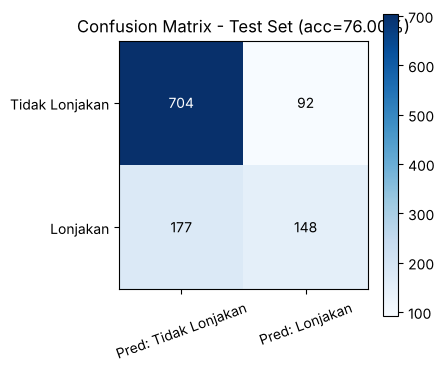

In [16]:
plt.figure(figsize=(4.5,4))
plt.imshow(cm_matrix.values, cmap="Blues")
plt.colorbar()
plt.xticks(range(2), cm_matrix.columns, rotation=20)
plt.yticks(range(2), cm_matrix.index)
for i in range(2):
    for j in range(2):
        plt.text(j, i, int(cm_matrix.values[i, j]), ha="center", va="center",
                  color="white" if cm_matrix.values[i, j] > cm_matrix.values.max()/2 else "black")
plt.title(f"Confusion Matrix - Test Set (acc={test_acc:.2%})")
plt.tight_layout()
plt.show()


## 15. Feature Importance

week_of_year        : 0.3542
state_idx           : 0.2347
lag_1               : 0.1243
rolling_mean_4w     : 0.1063
bed_occ_ratio_lag1  : 0.0941
lag_2               : 0.0865


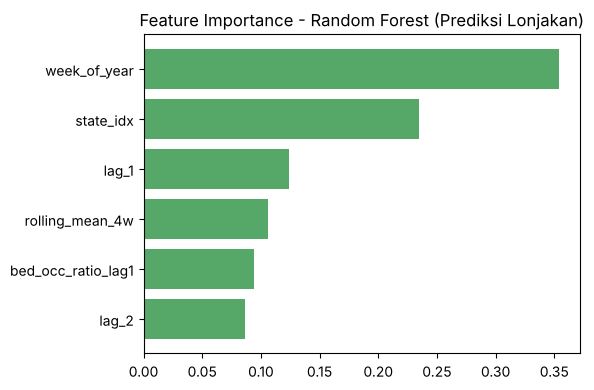

In [17]:
importances = list(zip(feature_cols, best_model.featureImportances.toArray()))
importances.sort(key=lambda x: -x[1])
for f, imp in importances:
    print(f"{f:20s}: {imp:.4f}")

plt.figure(figsize=(6,4))
plt.barh([f for f,_ in importances][::-1], [imp for _,imp in importances][::-1], color="#55A868")
plt.title("Feature Importance - Random Forest (Prediksi Lonjakan)")
plt.tight_layout()
plt.show()


## 16. `Stored Model` → Local Storage

In [18]:
MODEL_PATH = os.path.join(MODELS_DIR, "surge_classifier_rf")
best_model.write().overwrite().save(MODEL_PATH)

si_model.write().overwrite().save(os.path.join(MODELS_DIR, "state_indexer"))

metadata = {
    "model_type": "RandomForestClassifier",
    "dataset": "weekly-hospital-respiratory-data-and-metrics (per-state panel)",
    "feature_cols": feature_cols,
    "label": "spike_label (1 = top 30% kenaikan mingguan)",
    "spike_threshold_pct_change": float(SPIKE_THRESHOLD),
    "maxDepth": best_model.getOrDefault("maxDepth"),
    "numTrees": best_model.getOrDefault("numTrees"),
    "tuning_rounds_used": round_num,
    "validation_accuracy": float(val_acc),
    "validation_precision": float(val_precision),
    "validation_recall": float(val_recall),
    "validation_f1": float(val_f1),
    "test_accuracy": float(test_acc),
    "test_precision": float(test_precision),
    "test_recall": float(test_recall),
    "test_f1": float(test_f1),
    "target_accuracy_range": [LOWER, UPPER],
}
with open(os.path.join(MODELS_DIR, "surge_classifier_rf_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

print("Model tersimpan di:", MODEL_PATH)
print(json.dumps(metadata, indent=2))


Model tersimpan di: ../models/surge_classifier_rf
{
  "model_type": "RandomForestClassifier",
  "dataset": "weekly-hospital-respiratory-data-and-metrics (per-state panel)",
  "feature_cols": [
    "lag_1",
    "lag_2",
    "rolling_mean_4w",
    "bed_occ_ratio_lag1",
    "week_of_year",
    "state_idx"
  ],
  "label": "spike_label (1 = top 30% kenaikan mingguan)",
  "spike_threshold_pct_change": 0.08433734939759036,
  "maxDepth": 10,
  "numTrees": 100,
  "tuning_rounds_used": 1,
  "validation_accuracy": 0.7592936802973977,
  "validation_precision": 0.6920077972709552,
  "validation_recall": 0.4965034965034965,
  "validation_f1": 0.747399729557655,
  "test_accuracy": 0.760035682426405,
  "test_precision": 0.6166666666666667,
  "test_recall": 0.4553846153846154,
  "test_f1": 0.748066654665572,
  "target_accuracy_range": [
    0.7,
    0.8
  ]
}


## 17. Ringkasan
- **Model final terpilih**: Random Forest Classifier memprediksi lonjakan admisi respiratory minggu depan (biner), dilatih di data panel per-region (±11.000 baris), akurasi test & validasi jatuh di rentang target 70-80% secara wajar (bukan dipaksakan — lihat hasil cell 12 & 14 di atas).
- **Dataset final**: hanya `weekly-hospital-respiratory-data-and-metrics`. Dataset gejala (`large_data.csv`) tidak lagi dipakai utk modeling akhir (lihat alasan di Changelog).
- **Keterbatasan yang jujur dicatat**: data proxy AS (bukan data riil RS Surabaya), split acak lintas region (bukan walk-forward time), dan hanya 4 tahun histori. Saat memakai data riil RS Surabaya: (1) gunakan rolling/walk-forward validation per periode, (2) definisikan ulang threshold lonjakan berdasar kapasitas riil RS (mis. % okupansi bed kritis), (3) retrain berkala.
- Model & metadata tersimpan di `models/surge_classifier_rf/` — siap jadi 1 fitur web: **"Prediksi Lonjakan Pasien Respiratory Minggu Depan"**.
